# 1. Libraries

In [58]:
# Import pandas
import pandas as pd

# Import numpy
import numpy as np

# Import seaborn for plotting
import seaborn as sns

# Set style of seaborn library 
sns.set_style("darkgrid")

# Import matplotlib for plotting
from matplotlib import pyplot as plt

# Import TensorFlow
import tensorflow as tf

# 2. Modules

In [59]:
from data_module import *

from evaluation_module import *

from linear_module import *

from non_linear_module import *

# Ignore warnings about dependencies on deprecated TF features
tf.logging.set_verbosity(tf.logging.ERROR)

# 3. Raw Data

### 3.1 Specification

In [60]:
# Specify time period 
Start = "01/31/1986" 
End = "12/31/2018" 

# Define feature variables 
Features_v = ["Momentum_12_1M", "BookToPrice", "Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
              "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
              "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
              "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

# Define return variable 
Return_v = "TotalReturnUSD"

# Define market size variable 
Size_v = "Mcap_BMI_USD"

# Specify method (rolling or expanding)
Method = "rolling"  

# Specify after how many month the model is refitted 
Refit = 12

# Specify years of rolling window/min years of expanding method
Years = 10

# Specify number of portfolios for backtesting
N = 10

# Specify validation method: walk-forward (wf) or blocking walk-forward (bwf)
Validation = "wf"

# Specify the years used for validation.
Val_size=1

# Specify number of splits for validation
N_splits=3

### 3.2 Import 

In [61]:
# Import data 
Features, Return, Response, Size = import_data(Features=Features_v, 
                                               Return=Return_v, 
                                               Size=Size_v, 
                                               Start=Start, 
                                               End=End)

# 4. Data Processing

### 4.1 Take log of Size feature

In [62]:
# Take log of size variable
Features.loc[:,"Mcap_BMI_USD"] = Features.loc[:,"Mcap_BMI_USD"].apply(np.log)

# Rename column
Features.rename(columns={"Mcap_BMI_USD":"log_Mcap_BMI_USD"}, inplace=True)

### 4.2 Concat Data and drop NAs

In [63]:
# Concat variables
Data = pd.concat([Features, Return, Response, Size], axis=1)

# Drop inf and NAs
Data = Data.replace([np.inf, -np.inf], np.nan).dropna(how="any")

### 4.3 Winsorize features

In [64]:
# Winsorize features 
Data = winsorize_panel(Panel_Data=Data, 
                       Features=Features.columns, 
                       Upper=0.01, 
                       Lower=0.01)

### 4.4 Show Statistics

In [65]:
# Compute statistics
Data_stats = stats_panel(Panel_Data=Data, 
                         Variables=list(Features.columns)+[Return_v])

# Show statistics
Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


### 4.5 Demean Return

In [66]:
# Demean return variable
Data = demean(Data=Data, Variable=['TotalReturnUSD t+1', 'TotalReturnUSD'])

# 5 Neural Networks

### 5.1 Specification

In [67]:
# Define features for neural network
NN_raw_Features = ["Momentum_12_1M", "BookToPrice", "log_Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
                   "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
                   "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
                   "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

### 5.2 Data

In [68]:
# Gather data
NN_raw_Data = gather_data(Data=Data, 
                         Features=NN_raw_Features)

# Compute statistics
NN_raw_Data_stats = stats_panel(Panel_Data=NN_raw_Data, 
                               Variables=NN_raw_Features+[Return_v])

# Show statistics
NN_raw_Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


### 5.3 Hyperparameter

Importtant Hyperparameters:

1. Penalty (l_1, l_2, or l1_l2)
2. Dropout rate (dropout_rate)
3. Hidden layers

# NN1

### 5.4 Fit + Predictions

In [91]:
# Run neural networks and make predictions
NN1_raw_Pre, \
NN1_raw_Pre_stats, \
NN1_raw_Params, \
Years = neural_net(Data=NN_raw_Data,             # data
                   Features=NN_raw_Features,     # feature variables 
                   Response=Response.columns,    # response variable  
                   Method=Method,                # rolling or expanding method
                   Years=Years,                  # years of rolling window/min years of expanding
                   Refit=Refit,                  # months after which the model is refitted
                   Stats=True,                   # whether to compute summary statistics
                   Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
                   Val_size=Val_size,            # validation size
                   N_splits=N_splits,            # number of splits   
                   Name="NN1",                   # Name for graph
                   Penalty="l1_l2",              # l1, l2, or l1_l2
                   Hidden_layers=[21],           # hidden layers
                   Optimizer='adam',             # optimizer
                   Batch_size=128,               # batch size
                   Epochs=15,                    # epochs
                   ES=False,                     # early stopping
                   Patience=3,                   # patience of early stopping
                   Verbose=True,                 # whether to print status 
                   Param_grid=[{"l1_penalty": [0],        # l1 penalty options
                                "l2_penalty": [0],        # l2 penalty options
                                "dropout_rate": [0]}])    # dropout rate options

# Show stats for predictions
NN1_raw_Pre_stats

1. Iteration completed
2. Iteration completed
3. Iteration completed
4. Iteration completed
5. Iteration completed
6. Iteration completed
7. Iteration completed
8. Iteration completed
9. Iteration completed
10. Iteration completed
11. Iteration completed
12. Iteration completed
13. Iteration completed
14. Iteration completed
15. Iteration completed
16. Iteration completed
17. Iteration completed
18. Iteration completed
19. Iteration completed
20. Iteration completed
Running time = 3.03 hours


,Prediction
Avg,0.09
Std,0.90
p10,-0.88
p90,1.07


### 5.5 Evaluation

In [92]:
# Create evaluation table
NN1_raw_Eval_Data = eval_data(Data=NN_raw_Data, 
                              Predictions=NN1_raw_Pre, 
                              Return=Return_v, 
                              Size=Size_v)

# Create Portfolios
NN1_raw_Eval_Port, NN1_raw_Eval_Port_cRet = portfolios(Eval_Data=NN1_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
NN1_raw_Eval_Reg = linear_eval_reg(Eval_Data=NN1_raw_Eval_Data)

# Show statistic
NN1_raw_Eval_Reg

,Prediction
Slope,0.51
S.E.,0.06
t-stat,8.17


### cum. Outperformance 

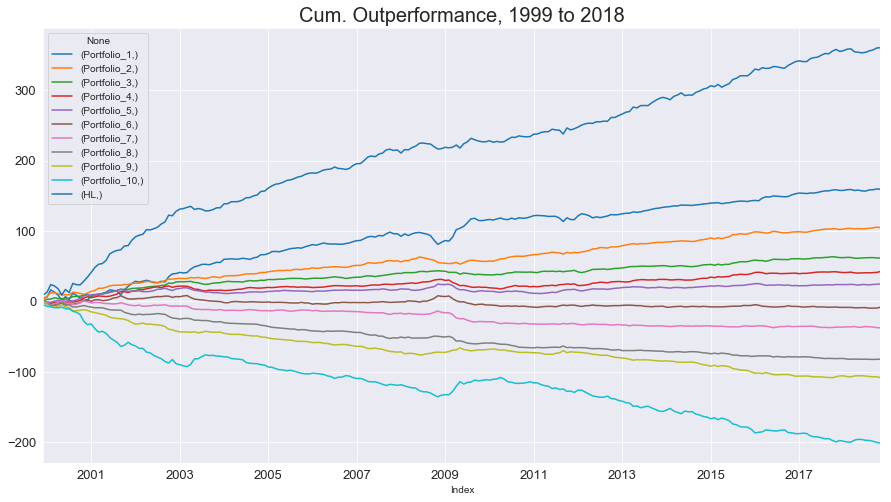

In [93]:
NN1_raw_Eval_Port_cRet[NN1_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Cum. Outperformance, %.0f to %.0f" 
% (NN1_raw_Eval_Data.index[0][0].year, NN1_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

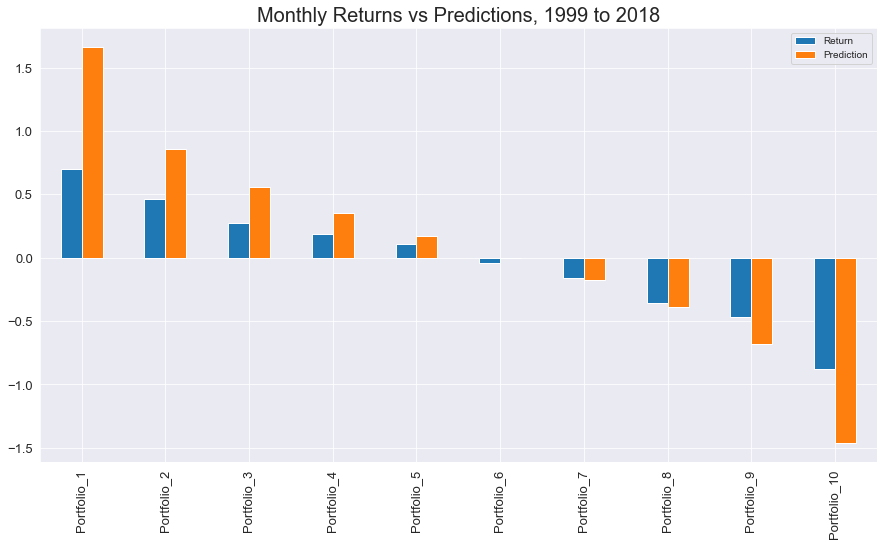

In [94]:
NN1_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (NN1_raw_Eval_Data.index[0][0].year, NN1_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

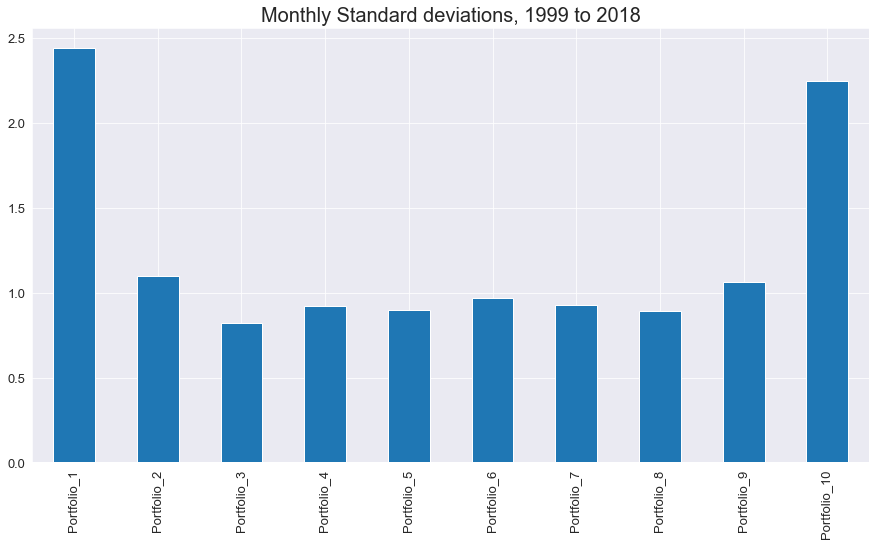

In [95]:
NN1_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (NN1_raw_Eval_Data.index[0][0].year, NN1_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

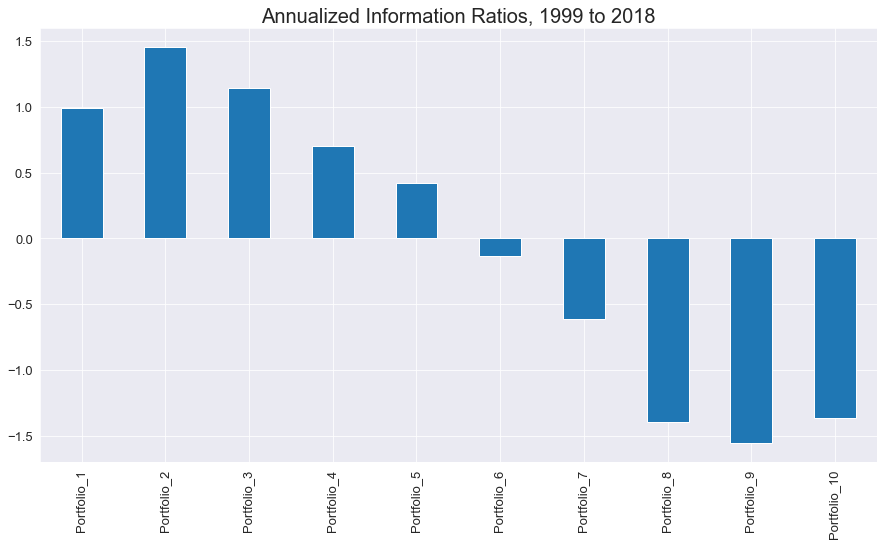

In [96]:
NN1_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (NN1_raw_Eval_Data.index[0][0].year, NN1_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 5.6 Store Model

In [97]:
# Store dataframes 
NN1_raw_Eval_Port.to_pickle("NN1_raw_Eval_Port")
NN1_raw_Eval_Reg.to_pickle("NN1_raw_Eval_Reg")
NN1_raw_Eval_Port_cRet.to_pickle("NN1_raw_Eval_Port_cRet")

# NN2 

### 5.4 Fit + Predictions

In [76]:
# Run neural networks and make predictions
NN2_raw_Pre, \
NN2_raw_Pre_stats, \
NN2_raw_Params, \
Years = neural_net(Data=NN_raw_Data,             # data
                   Features=NN_raw_Features,     # feature variables 
                   Response=Response.columns,    # response variable  
                   Method=Method,                # rolling or expanding method
                   Years=Years,                  # years of rolling window/min years of expanding
                   Refit=Refit,                  # months after which the model is refitted
                   Stats=True,                   # whether to compute summary statistics
                   Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
                   Val_size=Val_size,            # validation size
                   N_splits=N_splits,            # number of splits   
                   Name="NN2",                   # Name for graph
                   Penalty="l1_l2",              # l1, l2, or l1_l2
                   Hidden_layers=[21,10],        # hidden layers
                   Optimizer='adam',             # optimizer
                   Batch_size=128,               # batch size
                   Epochs=10,                    # epochs
                   ES=False,                     # early stopping
                   Patience=3,                   # patience of early stopping
                   Verbose=True,                 # whether to print status 
                   Param_grid=[{"l1_penalty": [0],        # l1 penalty options
                                "l2_penalty": [0],        # l2 penalty options
                                "dropout_rate": [0]}])    # dropout rate options

# Show stats for predictions
NN2_raw_Pre_stats

1. Iteration completed
2. Iteration completed
3. Iteration completed
4. Iteration completed
5. Iteration completed
6. Iteration completed
7. Iteration completed
8. Iteration completed
9. Iteration completed
10. Iteration completed
11. Iteration completed
12. Iteration completed
13. Iteration completed
14. Iteration completed
15. Iteration completed
16. Iteration completed
17. Iteration completed
18. Iteration completed
19. Iteration completed
20. Iteration completed
Running time = 2.33 hours


,Prediction
Avg,-0.03
Std,0.89
p10,-1.04
p90,0.93


### 5.5 Evaluation

In [77]:
# Create evaluation table
NN2_raw_Eval_Data = eval_data(Data=NN_raw_Data, 
                              Predictions=NN2_raw_Pre, 
                              Return=Return_v, 
                              Size=Size_v)

# Create Portfolios
NN2_raw_Eval_Port, NN2_raw_Eval_Port_cRet = portfolios(Eval_Data=NN2_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
NN2_raw_Eval_Reg = linear_eval_reg(Eval_Data=NN2_raw_Eval_Data)

# Show statistic
NN2_raw_Eval_Reg

,Prediction
Slope,0.51
S.E.,0.06
t-stat,7.95


### cum. Outperformance

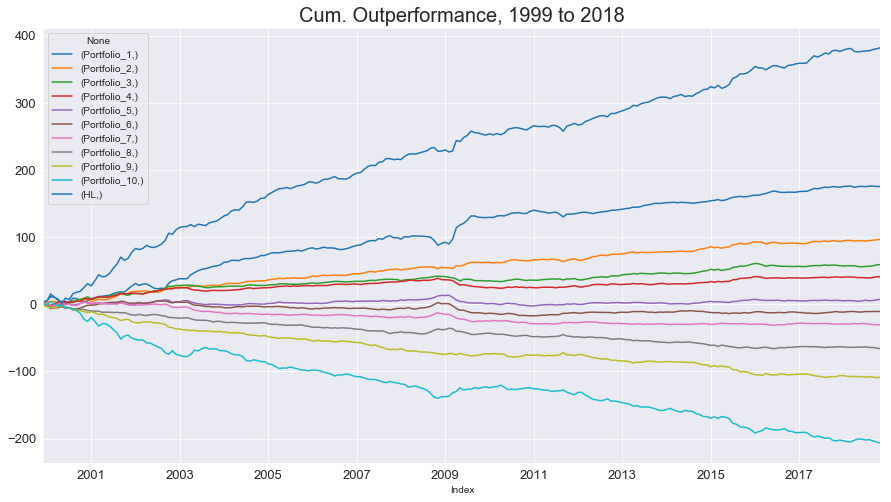

In [78]:
NN2_raw_Eval_Port_cRet[NN2_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Cum. Outperformance, %.0f to %.0f" 
% (NN2_raw_Eval_Data.index[0][0].year, NN2_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

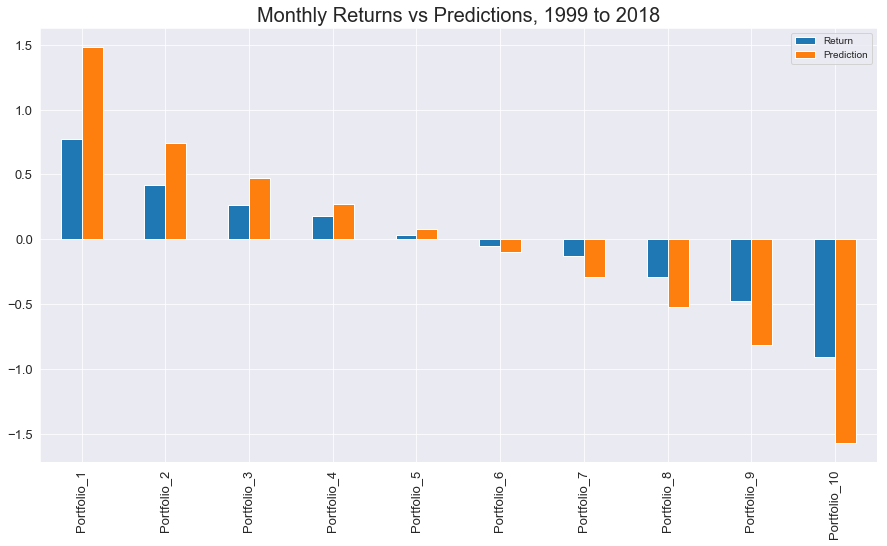

In [79]:
NN2_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (NN2_raw_Eval_Data.index[0][0].year, NN2_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

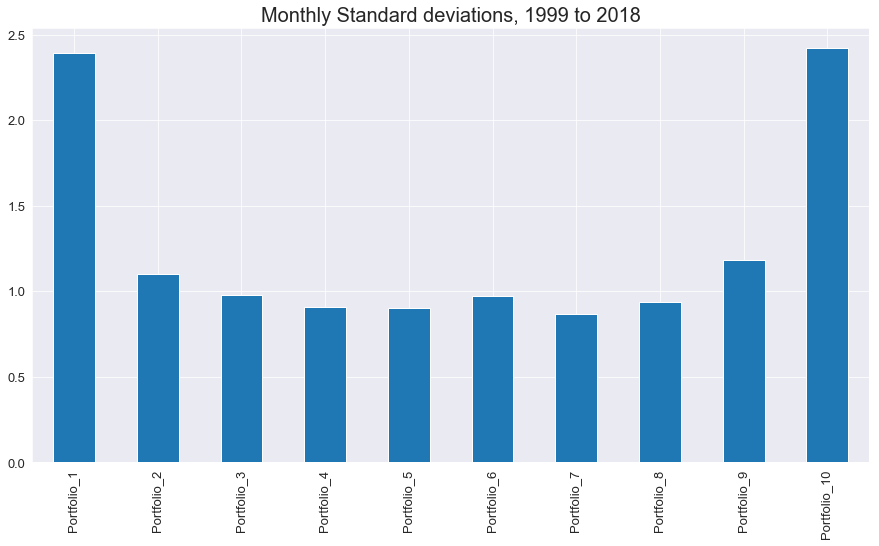

In [80]:
NN2_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (NN2_raw_Eval_Data.index[0][0].year, NN2_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

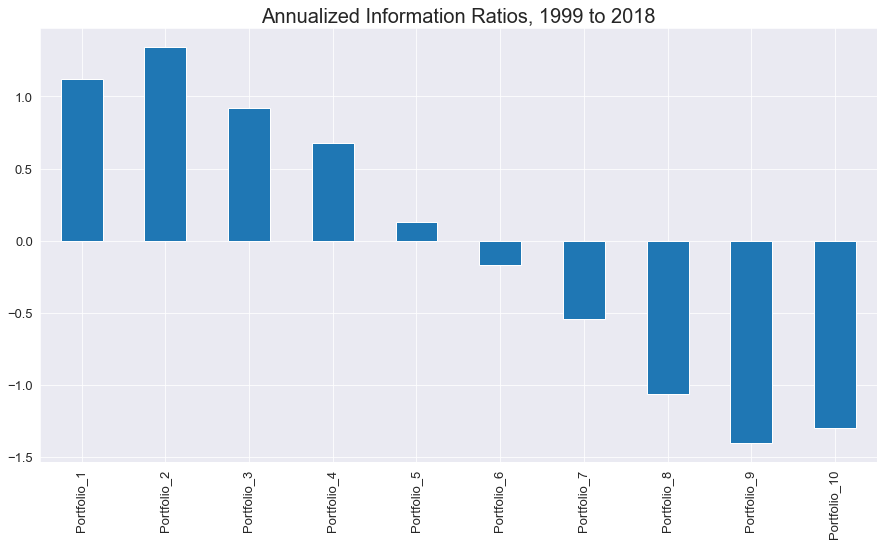

In [81]:
NN2_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (NN2_raw_Eval_Data.index[0][0].year, NN2_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 5.6 Store Model

In [82]:
# Store dataframes 
NN2_raw_Eval_Port.to_pickle("NN2_raw_Eval_Port")
NN2_raw_Eval_Reg.to_pickle("NN2_raw_Eval_Reg")
NN2_raw_Eval_Port_cRet.to_pickle("NN2_raw_Eval_Port_cRet")

# NN3

### 5.4 Fit + Predictions

In [83]:
# Run neural networks and make predictions
NN3_raw_Pre, \
NN3_raw_Pre_stats, \
NN3_raw_Params, \
Years = neural_net(Data=NN_raw_Data,             # data
                   Features=NN_raw_Features,     # feature variables 
                   Response=Response.columns,    # response variable  
                   Method=Method,                # rolling or expanding method
                   Years=Years,                  # years of rolling window/min years of expanding
                   Refit=Refit,                  # months after which the model is refitted
                   Stats=True,                   # whether to compute summary statistics
                   Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
                   Val_size=Val_size,            # validation size
                   N_splits=N_splits,            # number of splits                 
                   Penalty="l1_l2",              # l1, l2, or l1_l2
                   Name="NN3",                   # Name for graph
                   Hidden_layers=[21,10,5],      # hidden layers
                   Optimizer='adam',             # optimizer
                   Batch_size=128,               # batch size
                   Epochs=10,                    # epochs
                   ES=False,                     # early stopping
                   Patience=3,                   # patience of early stopping
                   Verbose=True,                 # whether to print status 
                   Param_grid=[{"l1_penalty": [0],        # l1 penalty options  
                                "l2_penalty": [0],        # l2 penalty options
                                "dropout_rate": [0]}])     # dropout rate options

# Show stats for predictions
NN3_raw_Pre_stats

1. Iteration completed
2. Iteration completed
3. Iteration completed
4. Iteration completed
5. Iteration completed
6. Iteration completed
7. Iteration completed
8. Iteration completed
9. Iteration completed
10. Iteration completed
11. Iteration completed
12. Iteration completed
13. Iteration completed
14. Iteration completed
15. Iteration completed
16. Iteration completed
17. Iteration completed
18. Iteration completed
19. Iteration completed
20. Iteration completed
Running time = 2.46 hours


,Prediction
Avg,0.02
Std,0.83
p10,-0.95
p90,0.85


### 5.5 Evaluation

In [84]:
# Create evaluation table
NN3_raw_Eval_Data = eval_data(Data=NN_raw_Data, 
                              Predictions=NN3_raw_Pre, 
                              Return=Return_v, 
                              Size=Size_v)

# Create Portfolios
NN3_raw_Eval_Port, NN3_raw_Eval_Port_cRet = portfolios(Eval_Data=NN3_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
NN3_raw_Eval_Reg = linear_eval_reg(Eval_Data=NN3_raw_Eval_Data)

# Show statistic
NN3_raw_Eval_Reg

,Prediction
Slope,0.60
S.E.,0.07
t-stat,8.68


### cum. Outperformance

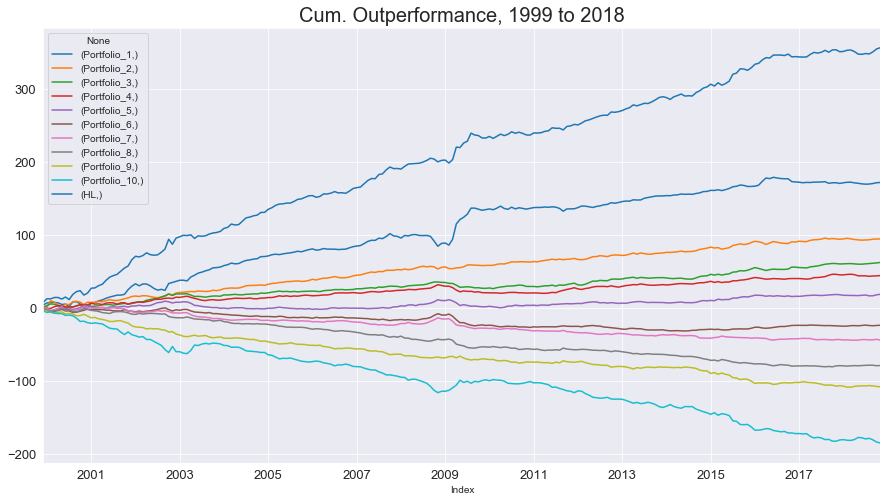

In [85]:
NN3_raw_Eval_Port_cRet[NN3_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Cum. Outperformance, %.0f to %.0f" 
% (NN3_raw_Eval_Data.index[0][0].year, NN3_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

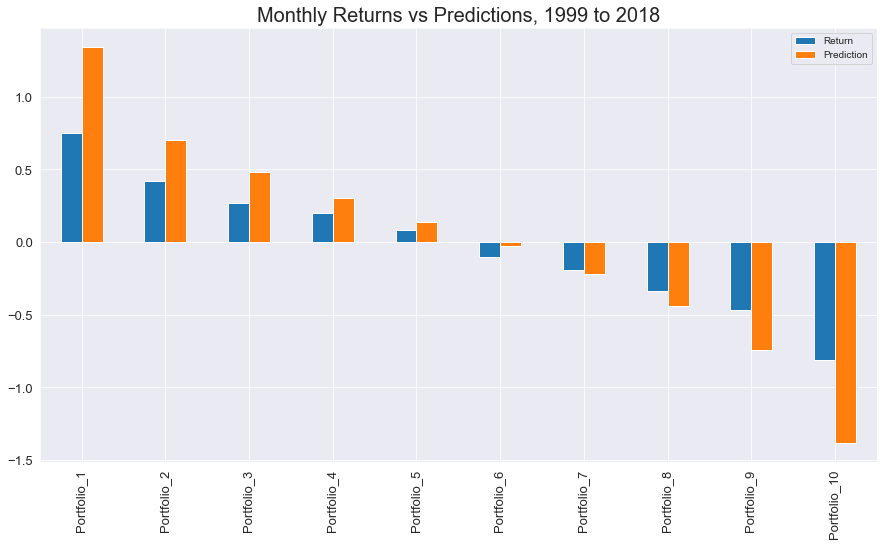

In [86]:
NN3_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (NN3_raw_Eval_Data.index[0][0].year, NN3_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

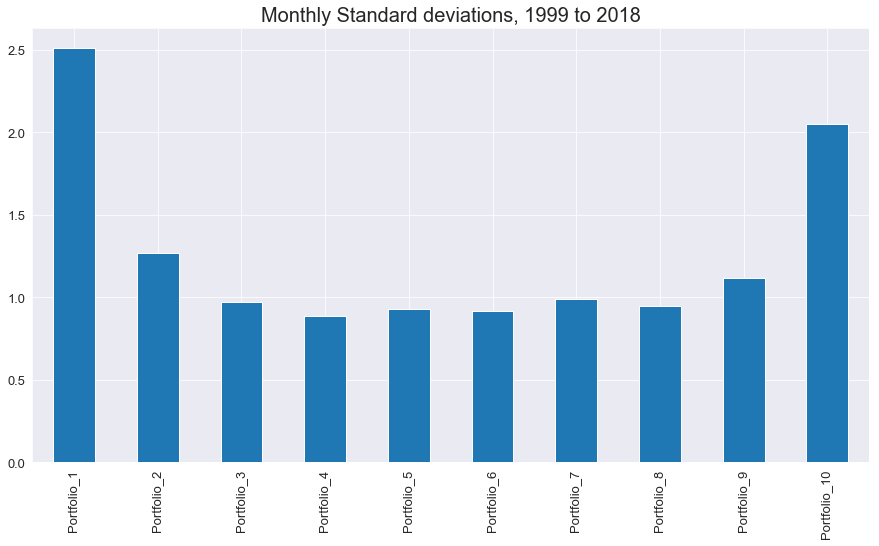

In [87]:
NN3_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (NN3_raw_Eval_Data.index[0][0].year, NN3_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

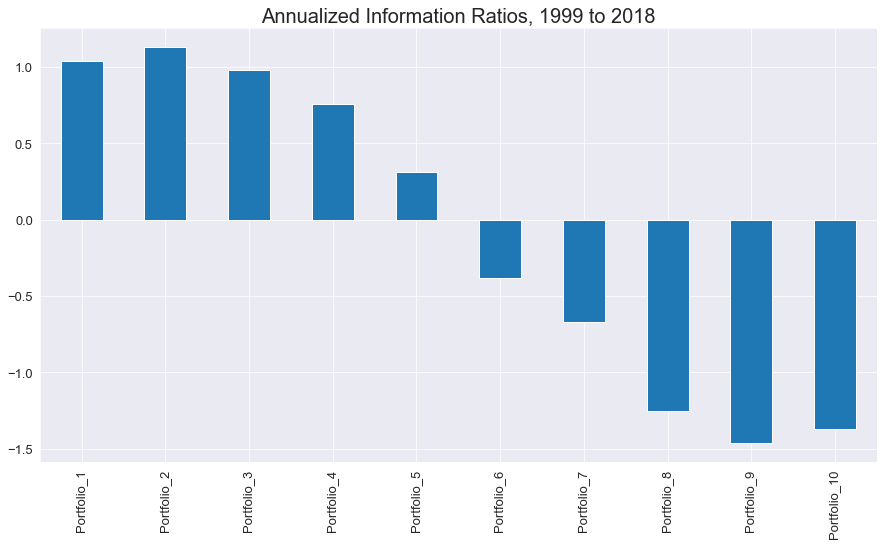

In [88]:
NN3_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (NN3_raw_Eval_Data.index[0][0].year, NN3_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 5.6 Store Model

In [89]:
# Store dataframes 
NN3_raw_Eval_Port.to_pickle("NN3_raw_Eval_Port")
NN3_raw_Eval_Reg.to_pickle("NN3_raw_Eval_Reg")
NN3_raw_Eval_Port_cRet.to_pickle("NN3_raw_Eval_Port_cRet")

# 6. Comparison 

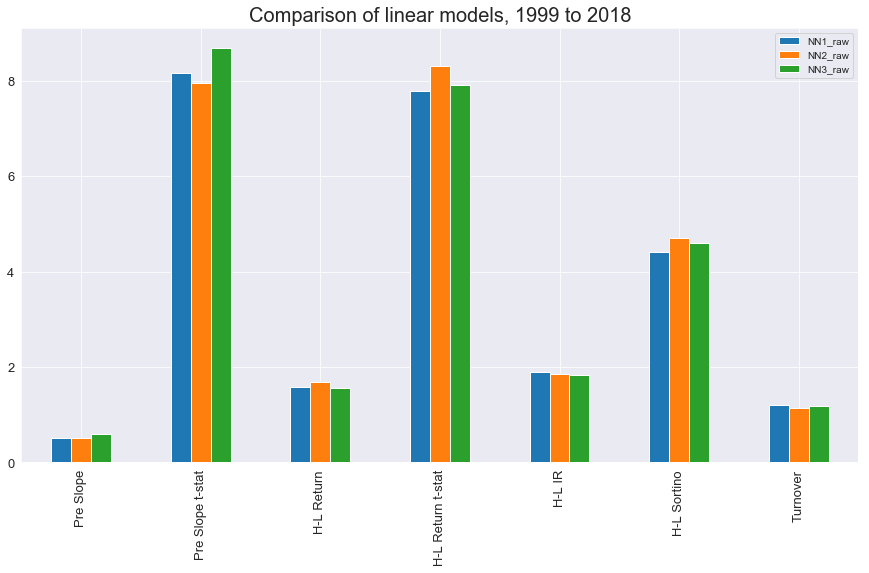

In [98]:
# Compare models
compare(Models = ["NN1_raw", "NN2_raw", "NN3_raw"], Plot=False, Globals=globals()).plot.bar(
figsize=[15,8],
fontsize=13,
title ="Comparison of linear models, %.0f to %.0f" 
% ((Data.index[0][0] + pd.offsets.BMonthEnd(Years*12)).year, Data.index[-1][0].year)).title.set_size(20);